# AIML Practical 3

## Performance Evaluation of Regression Models and Gradient Descent using California House Price Prediction

**Name:** Siddhesh Abasaheb Mane  
**PRN:** 202401040187  
**Batch:** A2  
**Roll No.:** 46

---

## Objective

1. Develop regression models for a real-world application and evaluate their performance using appropriate metrics.
2. Implement and analyse Gradient Descent optimisation for Linear Regression.
3. Study Simple Linear Regression, Multiple Linear Regression, Polynomial Regression and the Least Squares Method.
4. Compare implementations using library functions with implementations developed manually.
5. Explore Lasso Regression, Ridge Regression and Locally Weighted Linear Regression (extra-mark topics).

## Problem Statement

House value estimation is a regression problem because the target variable is continuous. The objective is to predict median house value from housing and geographic attributes and compare different regression and optimisation techniques.

## Dataset

The California Housing dataset contains 20,640 census block-group observations and eight numerical predictors. The target is `MedHouseVal`, measured in units of $100,000.

| Feature | Description |
|---|---|
| MedInc | Median income |
| HouseAge | Median house age |
| AveRooms | Average rooms per household |
| AveBedrms | Average bedrooms per household |
| Population | Block-group population |
| AveOccup | Average household occupancy |
| Latitude | Latitude |
| Longitude | Longitude |
| MedHouseVal | Target: median house value, units of $100,000 |

**Implementation order:** For Simple, Multiple and Polynomial Regression, the manual implementation is shown before the corresponding Scikit-learn implementation. All models use the same train/test split for a fair comparison. Preprocessing statistics are calculated only from the training data.

## 1. Import Required Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations_with_replacement
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the California Housing Dataset

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset shape:", df.shape)
print("Number of observations:", df.shape[0])
print("Number of predictors:", df.shape[1] - 1)
display(df.head())

Dataset shape: (20640, 9)
Number of observations: 20640
Number of predictors: 8


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Inspect the Dataset

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## 4. Exploratory Data Analysis

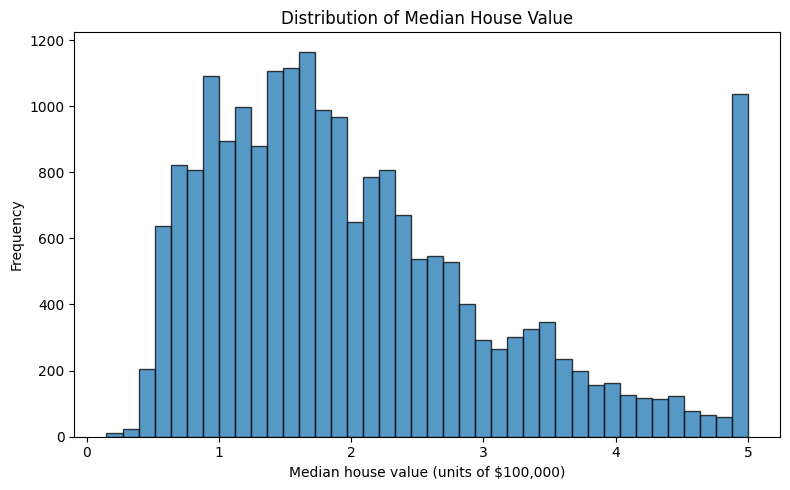

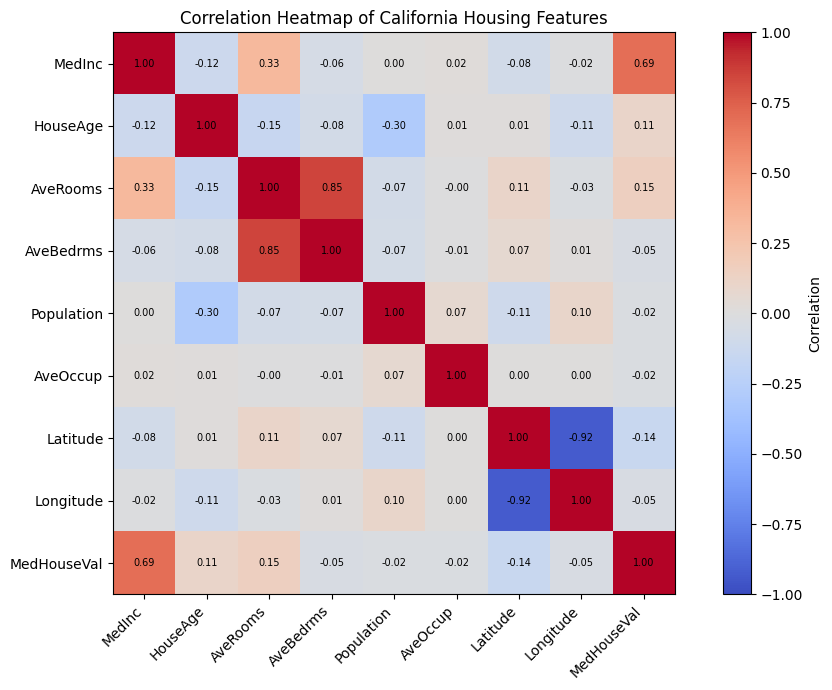

In [4]:
# Distribution of the target variable
plt.figure(figsize=(8, 5))
plt.hist(df["MedHouseVal"], bins=40, edgecolor="black", alpha=0.75)
plt.title("Distribution of Median House Value")
plt.xlabel("Median house value (units of $100,000)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
corr = df.corr()
image = plt.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
for row in range(len(corr.columns)):
    for col in range(len(corr.columns)):
        plt.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation Heatmap of California Housing Features")
plt.tight_layout()
plt.show()

## 5. Define X and y; Split the Dataset

In [5]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


## 6. Define Regression Evaluation Metrics

- **MAE:** Mean Absolute Error; average absolute prediction error. Lower is better.
- **MSE:** Mean Squared Error; penalises larger errors more strongly. Lower is better.
- **RMSE:** Square root of MSE; expressed in the same units as the target. Lower is better.
- **R²:** Coefficient of determination. A value closer to 1 indicates that the model explains more variation in the target.

In [6]:
def evaluate_regression(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

results = []
print("Evaluation function is ready.")

Evaluation function is ready.


## 7. Model 1A — Simple Linear Regression Without Scikit-learn (Least Squares)

Simple Linear Regression uses one independent variable. Here, `MedInc` (median income) is used to estimate median house value.

The least-squares slope and intercept are calculated directly from the training observations:

\[
b_1=\frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}{\sum_i(x_i-\bar{x})^2},\qquad b_0=\bar{y}-b_1\bar{x}
\]

The prediction equation is \(\hat y=b_0+b_1x\). This section demonstrates the Least Squares Method without using a ready-made regression estimator.

Slope: 0.419338493938127
Intercept: 0.4445972916907883
Regression equation: y = 0.444597 + 0.419338 * MedInc

Simple Linear Regression (from scratch) metrics:
{'MAE': 0.629908653009376, 'MSE': 0.7091157771765549, 'RMSE': np.float64(0.8420901241414455), 'R2': 0.45885918903846656}


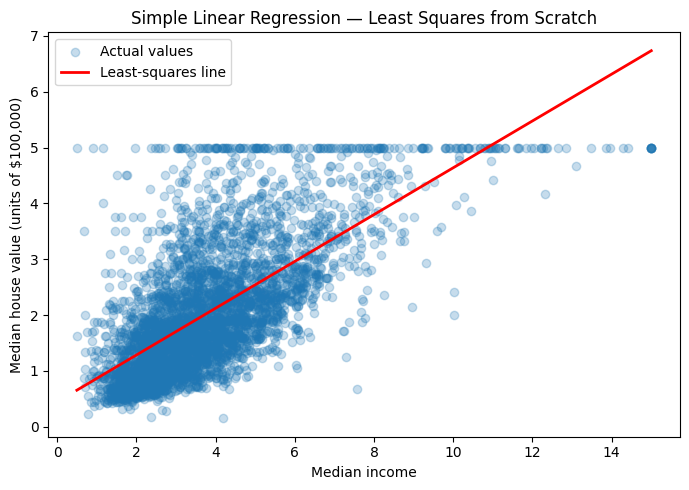

In [7]:
# Use only median income as the predictor
x_train_simple = X_train["MedInc"].to_numpy(dtype=float)
x_test_simple = X_test["MedInc"].to_numpy(dtype=float)
y_train_np = y_train.to_numpy(dtype=float)

# Calculate means using training data
x_mean = np.mean(x_train_simple)
y_mean = np.mean(y_train_np)

# Least-squares slope and intercept
numerator = np.sum((x_train_simple - x_mean) * (y_train_np - y_mean))
denominator = np.sum((x_train_simple - x_mean) ** 2)

slope_simple_scratch = numerator / denominator
intercept_simple_scratch = y_mean - slope_simple_scratch * x_mean

print("Slope:", slope_simple_scratch)
print("Intercept:", intercept_simple_scratch)
print(f"Regression equation: y = {intercept_simple_scratch:.6f} + {slope_simple_scratch:.6f} * MedInc")

simple_scratch_pred = intercept_simple_scratch + slope_simple_scratch * x_test_simple
simple_scratch_metrics = evaluate_regression(y_test, simple_scratch_pred)

print("\nSimple Linear Regression (from scratch) metrics:")
print(simple_scratch_metrics)
results.append({"Model": "Simple Linear Regression (Scratch)", **simple_scratch_metrics})

plt.figure(figsize=(7, 5))
plt.scatter(x_test_simple, y_test, alpha=0.25, label="Actual values")
order = np.argsort(x_test_simple)
plt.plot(x_test_simple[order], simple_scratch_pred[order], color="red", linewidth=2, label="Least-squares line")
plt.xlabel("Median income")
plt.ylabel("Median house value (units of $100,000)")
plt.title("Simple Linear Regression — Least Squares from Scratch")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Model 1B — Simple Linear Regression Using Scikit-learn

Now the same single-feature model is implemented using Scikit-learn's `LinearRegression`. Comparing the two implementations checks whether the manually calculated least-squares coefficients reproduce the library result.

In [8]:
simple_model = LinearRegression()
simple_model.fit(X_train[["MedInc"]], y_train)

simple_pred = simple_model.predict(X_test[["MedInc"]])
simple_metrics = evaluate_regression(y_test, simple_pred)

print("Intercept:", simple_model.intercept_)
print("MedInc coefficient:", simple_model.coef_[0])
print("Simple Linear Regression (Scikit-learn) metrics:")
print(simple_metrics)
results.append({"Model": "Simple Linear Regression (Scikit-learn)", **simple_metrics})

Intercept: 0.4445972916907879
MedInc coefficient: 0.4193384939381271
Simple Linear Regression (Scikit-learn) metrics:
{'MAE': 0.629908653009376, 'MSE': 0.7091157771765549, 'RMSE': np.float64(0.8420901241414455), 'R2': 0.45885918903846656}


## 9. Compare Simple Linear Regression Implementations

In [9]:
simple_comparison = pd.DataFrame([
    {"Implementation": "Manual Least Squares", **simple_scratch_metrics},
    {"Implementation": "Scikit-learn LinearRegression", **simple_metrics}
]).set_index("Implementation")

display(simple_comparison.round(6))

,MAE,MSE,RMSE,R2
Implementation,,,,
Manual Least Squares,0.629909,0.709116,0.84209,0.458859
Scikit-learn LinearRegression,0.629909,0.709116,0.84209,0.458859


## 10. Model 2A — Multiple Linear Regression Without Scikit-learn (Normal Equation)

Multiple Linear Regression uses all eight predictors. The Normal Equation computes coefficients by solving the least-squares problem:

\[\theta=(X^TX)^+X^Ty\]

Here, \((X^TX)^+\) denotes the Moore–Penrose pseudoinverse. `np.linalg.pinv` is used instead of a direct matrix inverse because it is more numerically stable when a matrix is singular or nearly singular.

Features are standardised using training-set means and standard deviations, and an intercept column is added manually.

In [10]:
X_train_np = X_train.to_numpy(dtype=float)
X_test_np = X_test.to_numpy(dtype=float)
y_train_np = y_train.to_numpy(dtype=float)

# Manual standardisation: fit statistics on training data only
feature_mean = np.mean(X_train_np, axis=0)
feature_std = np.std(X_train_np, axis=0)
feature_std[feature_std == 0] = 1.0

X_train_scaled_scratch = (X_train_np - feature_mean) / feature_std
X_test_scaled_scratch = (X_test_np - feature_mean) / feature_std

# Add intercept column
X_train_design = np.c_[np.ones(len(X_train_scaled_scratch)), X_train_scaled_scratch]
X_test_design = np.c_[np.ones(len(X_test_scaled_scratch)), X_test_scaled_scratch]

# Normal Equation using pseudoinverse
theta_normal = (
    np.linalg.pinv(X_train_design.T @ X_train_design)
    @ X_train_design.T @ y_train_np
)

print("Normal Equation coefficients (intercept first):")
print(theta_normal)

multiple_scratch_pred = X_test_design @ theta_normal
multiple_scratch_metrics = evaluate_regression(y_test, multiple_scratch_pred)

print("\nMultiple Linear Regression (Normal Equation) metrics:")
print(multiple_scratch_metrics)
results.append({"Model": "Multiple Linear Regression (Scratch Normal Equation)", **multiple_scratch_metrics})

Normal Equation coefficients (intercept first):
[ 2.07194694  0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772
 -0.0408291  -0.89692888 -0.86984178]

Multiple Linear Regression (Normal Equation) metrics:
{'MAE': 0.5332001304956553, 'MSE': 0.5558915986952445, 'RMSE': np.float64(0.7455813830127765), 'R2': 0.5757877060324507}


## 11. Model 2B — Multiple Linear Regression Using Scikit-learn

A pipeline standardises the eight predictors and fits Scikit-learn's `LinearRegression`. The scaler is fitted only on the training data and then applied to the test data.

In [11]:
multiple_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)
multiple_metrics = evaluate_regression(y_test, multiple_pred)

print("Multiple Linear Regression (Scikit-learn) metrics:")
print(multiple_metrics)
results.append({"Model": "Multiple Linear Regression (Scikit-learn)", **multiple_metrics})

Multiple Linear Regression (Scikit-learn) metrics:
{'MAE': 0.5332001304956565, 'MSE': 0.555891598695244, 'RMSE': np.float64(0.7455813830127761), 'R2': 0.5757877060324511}


## 12. Compare Multiple Linear Regression Implementations

In [12]:
multiple_comparison = pd.DataFrame([
    {"Implementation": "Manual Normal Equation", **multiple_scratch_metrics},
    {"Implementation": "Scikit-learn LinearRegression", **multiple_metrics}
]).set_index("Implementation")

display(multiple_comparison.round(6))

,MAE,MSE,RMSE,R2
Implementation,,,,
Manual Normal Equation,0.5332,0.555892,0.745581,0.575788
Scikit-learn LinearRegression,0.5332,0.555892,0.745581,0.575788


## 13. Model 3A — Polynomial Regression Without Scikit-learn

Polynomial Regression can represent nonlinear relationships by adding squared and interaction terms. For eight original features, a degree-2 expansion contains 8 original terms plus 36 terms of degree 2, giving 44 features in total.

The polynomial features are generated manually, and their coefficients are calculated using the least-squares pseudoinverse. Scaling statistics are fitted on the training data only.

In [13]:
# Standardise original features manually
poly_mean = np.mean(X_train_np, axis=0)
poly_std = np.std(X_train_np, axis=0)
poly_std[poly_std == 0] = 1.0

X_train_poly_scaled = (X_train_np - poly_mean) / poly_std
X_test_poly_scaled = (X_test_np - poly_mean) / poly_std

# Generate all unique degree-2 combinations (squares and interactions)
feature_pairs = list(combinations_with_replacement(range(X_train_np.shape[1]), 2))

def create_poly_features_manual(X_array):
    columns = [X_array]
    for i, j in feature_pairs:
        columns.append((X_array[:, i] * X_array[:, j]).reshape(-1, 1))
    return np.hstack(columns)

X_train_poly_manual = create_poly_features_manual(X_train_poly_scaled)
X_test_poly_manual = create_poly_features_manual(X_test_poly_scaled)

print("Original feature count:", X_train_np.shape[1])
print("Number of additional degree-2 terms:", len(feature_pairs))
print("Total polynomial feature count:", X_train_poly_manual.shape[1])

# Add intercept and solve least-squares problem
a_train_poly = np.c_[np.ones(len(X_train_poly_manual)), X_train_poly_manual]
a_test_poly = np.c_[np.ones(len(X_test_poly_manual)), X_test_poly_manual]

theta_poly_manual = np.linalg.pinv(a_train_poly) @ y_train_np
poly_scratch_pred = a_test_poly @ theta_poly_manual
poly_scratch_metrics = evaluate_regression(y_test, poly_scratch_pred)

print("\nPolynomial Regression (manual) metrics:")
print(poly_scratch_metrics)
results.append({"Model": "Polynomial Regression (Scratch)", **poly_scratch_metrics})

Original feature count: 8
Number of additional degree-2 terms: 36
Total polynomial feature count: 44

Polynomial Regression (manual) metrics:
{'MAE': 0.4670009334696588, 'MSE': 0.4643015238301219, 'RMSE': np.float64(0.6813967448044655), 'R2': 0.6456819729261907}


## 14. Model 3B — Polynomial Regression Using Scikit-learn

Scikit-learn's `PolynomialFeatures` generates the degree-2 terms, while `LinearRegression` fits their coefficients. The pipeline first standardises the original predictors.

In [14]:
polynomial_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
])

polynomial_model.fit(X_train, y_train)
polynomial_pred = polynomial_model.predict(X_test)
polynomial_metrics = evaluate_regression(y_test, polynomial_pred)

print("Polynomial feature count:", polynomial_model.named_steps["poly"].n_output_features_)
print("Polynomial Regression (Scikit-learn) metrics:")
print(polynomial_metrics)
results.append({"Model": "Polynomial Regression (Scikit-learn)", **polynomial_metrics})

Polynomial feature count: 44
Polynomial Regression (Scikit-learn) metrics:
{'MAE': 0.46700093346965726, 'MSE': 0.46430152383011997, 'RMSE': np.float64(0.6813967448044641), 'R2': 0.6456819729261921}


## 15. Compare Polynomial Regression Implementations

In [15]:
polynomial_comparison = pd.DataFrame([
    {"Implementation": "Manual Polynomial Features + Least Squares", **poly_scratch_metrics},
    {"Implementation": "Scikit-learn PolynomialFeatures + LinearRegression", **polynomial_metrics}
]).set_index("Implementation")

display(polynomial_comparison.round(6))

,MAE,MSE,RMSE,R2
Implementation,,,,
Manual Polynomial Features + Least Squares,0.467001,0.464302,0.681397,0.645682
Scikit-learn PolynomialFeatures + LinearRegression,0.467001,0.464302,0.681397,0.645682


## 16. Batch Gradient Descent — Prepare Data

Gradient Descent is an iterative optimisation method. It starts with initial coefficient values and repeatedly updates them in the direction that reduces the cost function.

For Linear Regression, the mean squared error cost can be minimised using the gradient of the cost with respect to the parameters. The predictors and target are standardised for stable optimisation. Scalers are fitted only on training data.

In [16]:
X_scaler_gd = StandardScaler()
y_scaler_gd = StandardScaler()

X_train_gd_scaled = X_scaler_gd.fit_transform(X_train)
X_test_gd_scaled = X_scaler_gd.transform(X_test)

y_train_gd_scaled = y_scaler_gd.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Add intercept column
X_train_gd = np.c_[np.ones(len(X_train_gd_scaled)), X_train_gd_scaled]
X_test_gd = np.c_[np.ones(len(X_test_gd_scaled)), X_test_gd_scaled]

print("Gradient Descent training matrix:", X_train_gd.shape)

Gradient Descent training matrix: (16512, 9)


## 17. Implement Batch Gradient Descent From Scratch

In [17]:
def batch_gradient_descent(X_matrix, y_vector, learning_rate=0.03, iterations=2000):
    m, n = X_matrix.shape
    theta = np.zeros(n)
    cost_history = []

    for iteration in range(iterations):
        predictions = X_matrix @ theta
        errors = predictions - y_vector

        # Cost function: sum of squared errors divided by 2m
        cost = np.sum(errors ** 2) / (2 * m)

        # Gradient of the cost function
        gradients = (X_matrix.T @ errors) / m

        # Update parameters
        theta = theta - learning_rate * gradients
        cost_history.append(cost)

    return theta, cost_history

alpha = 0.03
iterations = 2000

theta_gd, cost_history = batch_gradient_descent(
    X_train_gd,
    y_train_gd_scaled,
    learning_rate=alpha,
    iterations=iterations
)

print("Learned parameters:", theta_gd)
print("Initial recorded cost:", cost_history[0])
print("Final recorded cost:", cost_history[-1])

Learned parameters: [ 4.18521645e-15  7.43956141e-01  1.07860103e-01 -2.62076632e-01
  2.98695166e-01 -1.38860508e-03 -3.56129684e-02 -7.57568421e-01
 -7.34648688e-01]
Initial recorded cost: 0.5
Final recorded cost: 0.19374332889998946


## 18. Plot Gradient Descent Convergence

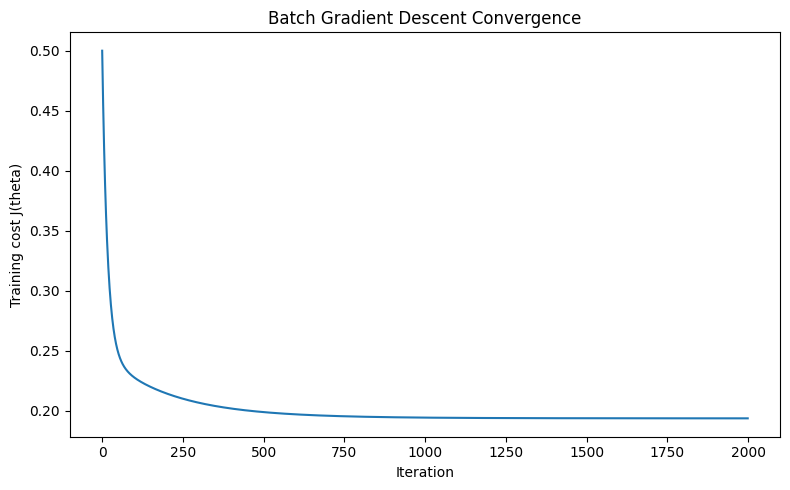

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Training cost J(theta)")
plt.title("Batch Gradient Descent Convergence")
plt.tight_layout()
plt.show()

## 19. Evaluate Batch Gradient Descent

In [19]:
# Predict on standardised test data
gd_pred_scaled = X_test_gd @ theta_gd

# Convert predictions back to original target units
gd_pred = y_scaler_gd.inverse_transform(
    gd_pred_scaled.reshape(-1, 1)
).ravel()

gd_metrics = evaluate_regression(y_test, gd_pred)
print("Batch Gradient Descent test metrics:")
print(gd_metrics)
results.append({"Model": "Multiple Linear Regression (Batch Gradient Descent)", **gd_metrics})

Batch Gradient Descent test metrics:
{'MAE': 0.5329688996290839, 'MSE': 0.5562556226758774, 'RMSE': np.float64(0.7458254639497618), 'R2': 0.5755099118577485}


## 20. Compare Batch Gradient Descent With Scikit-learn Multiple Linear Regression

In [20]:
gd_comparison = pd.DataFrame([
    {"Method": "Scikit-learn Multiple Linear Regression", **multiple_metrics},
    {"Method": "Manual Batch Gradient Descent", **gd_metrics}
]).set_index("Method")

display(gd_comparison.round(6))

,MAE,MSE,RMSE,R2
Method,,,,
Scikit-learn Multiple Linear Regression,0.533200,0.555892,0.745581,0.575788
Manual Batch Gradient Descent,0.532969,0.556256,0.745825,0.575510


## 21. Model 4 — Ridge Regression (L2 Regularisation)

Ridge Regression adds an L2 penalty to the regression objective. It discourages excessively large coefficients and can help reduce overfitting, particularly when predictors are correlated.

\[J(\theta)=\text{RSS}+\alpha\sum_{j=1}^{n}\theta_j^2\]

The intercept is not penalised by Scikit-learn's Ridge estimator. Predictors are standardised before fitting.

In [21]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_metrics = evaluate_regression(y_test, ridge_pred)

print("Ridge Regression metrics:")
print(ridge_metrics)
results.append({"Model": "Ridge Regression (alpha=1.0)", **ridge_metrics})

ridge_coefficients = ridge_model.named_steps["regressor"].coef_
display(pd.DataFrame({"Feature": X_train.columns, "Coefficient": ridge_coefficients}))

Ridge Regression metrics:
{'MAE': 0.5331931195789734, 'MSE': 0.5558548589435972, 'RMSE': np.float64(0.745556744281478), 'R2': 0.5758157428913683}


,Feature,Coefficient
0,MedInc,0.854327
1,HouseAge,0.122624
2,AveRooms,-0.294210
3,AveBedrms,0.339008
4,Population,-0.002282
5,AveOccup,-0.040833
6,Latitude,-0.896168
7,Longitude,-0.869071


## 22. Model 5 — Lasso Regression (L1 Regularisation)

Lasso Regression adds an L1 penalty to the regression objective. It can shrink some coefficients exactly to zero, which can act as a form of feature selection.

\[J(\theta)=\text{RSS}+\alpha\sum_{j=1}^{n}|\theta_j|\]

Predictors are standardised before fitting. The intercept is not penalised by Scikit-learn's Lasso estimator.

In [22]:
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=0.01, max_iter=20000))
])

lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
lasso_metrics = evaluate_regression(y_test, lasso_pred)

print("Lasso Regression metrics:")
print(lasso_metrics)
results.append({"Model": "Lasso Regression (alpha=0.01)", **lasso_metrics})

lasso_coefficients = lasso_model.named_steps["regressor"].coef_
lasso_coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_coefficients
})
display(lasso_coefficient_table)
print("Number of coefficients equal to zero:", int(np.sum(np.isclose(lasso_coefficients, 0))))

Lasso Regression metrics:
{'MAE': 0.5353261423609051, 'MSE': 0.5482548967938964, 'RMSE': np.float64(0.7404423656125414), 'R2': 0.5816154300698727}


,Feature,Coefficient
0,MedInc,0.800957
1,HouseAge,0.127087
2,AveRooms,-0.162759
3,AveBedrms,0.206207
4,Population,-0.000000
5,AveOccup,-0.030602
6,Latitude,-0.790113
7,Longitude,-0.755674


Number of coefficients equal to zero: 1


## 23. Compare Ridge and Lasso Regression

,MAE,MSE,RMSE,R2
Model,,,,
Ridge Regression,0.533193,0.555855,0.745557,0.575816
Lasso Regression,0.535326,0.548255,0.740442,0.581615


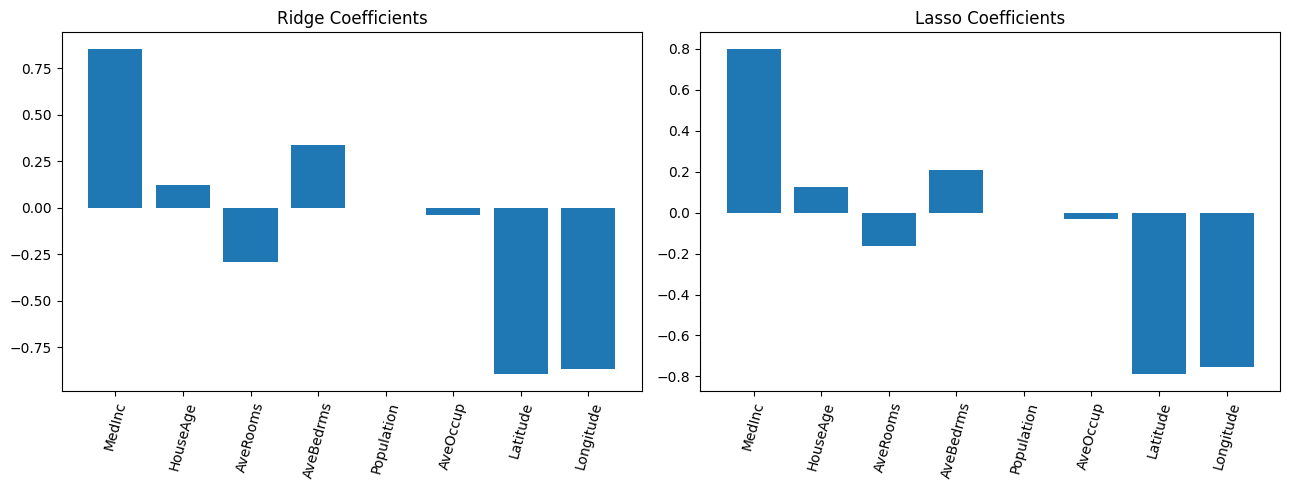

In [23]:
regularisation_comparison = pd.DataFrame([
    {"Model": "Ridge Regression", **ridge_metrics},
    {"Model": "Lasso Regression", **lasso_metrics}
]).set_index("Model")

display(regularisation_comparison.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(X_train.columns, ridge_coefficients)
axes[0].set_title("Ridge Coefficients")
axes[0].tick_params(axis="x", rotation=75)
axes[1].bar(X_train.columns, lasso_coefficients)
axes[1].set_title("Lasso Coefficients")
axes[1].tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

## 24. Model 6 — Locally Weighted Linear Regression (LWLR)

Locally Weighted Linear Regression is a non-parametric/local learning method. Instead of fitting one global line for every prediction, it fits a weighted linear regression around each query observation.

The Gaussian weight for a training observation is:

\[w_i=\exp\left(-\frac{d_i^2}{2\tau^2}\right)\]

where \(d_i\) is the Euclidean distance from the query point and \(\tau\) is the bandwidth. Nearby observations receive larger weights. The local coefficients are obtained by weighted least squares.

For computational efficiency, this implementation uses the 250 nearest training observations for each query point. It still produces predictions for the complete test set. The bandwidth and neighbour count are modelling choices and can affect results.

Completed 500 of 4128 LWLR predictions
Completed 1000 of 4128 LWLR predictions
Completed 1500 of 4128 LWLR predictions
Completed 2000 of 4128 LWLR predictions
Completed 2500 of 4128 LWLR predictions
Completed 3000 of 4128 LWLR predictions
Completed 3500 of 4128 LWLR predictions
Completed 4000 of 4128 LWLR predictions

Locally Weighted Linear Regression metrics:
Bandwidth (tau): 1.0
Nearest neighbours: 250
{'MAE': 0.39609100500085626, 'MSE': 0.3172443450354092, 'RMSE': np.float64(0.5632444806968011), 'R2': 0.7579043258225536}


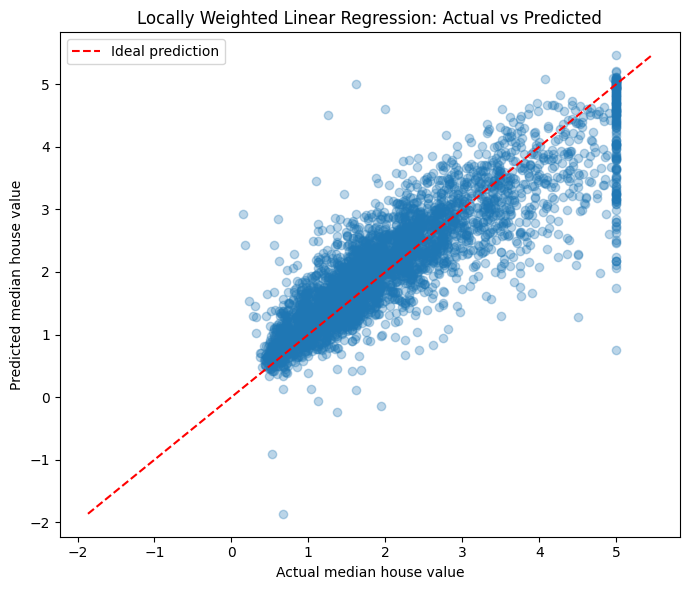

In [24]:
# Standardise predictors and target using training data only
lwlr_scaler = StandardScaler()
X_train_lwlr = lwlr_scaler.fit_transform(X_train)
X_test_lwlr = lwlr_scaler.transform(X_test)

lwlr_y_scaler = StandardScaler()
y_train_lwlr = lwlr_y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Find local neighbours in standardised feature space
K_NEIGHBORS = min(250, len(X_train))
neighbor_model = NearestNeighbors(n_neighbors=K_NEIGHBORS, algorithm="auto")
neighbor_model.fit(X_train_lwlr)
neighbor_distances, neighbor_indices = neighbor_model.kneighbors(X_test_lwlr)

def locally_weighted_regression(
    X_train_local, y_train_local, X_query,
    distances, indices, tau=1.0, regularization=1e-6
):
    predictions = np.empty(len(X_query), dtype=float)

    for row in range(len(X_query)):
        idx = indices[row]
        local_X = X_train_local[idx]
        local_y = y_train_local[idx]
        local_distances = distances[row]

        # Gaussian kernel weights
        weights = np.exp(-(local_distances ** 2) / (2 * tau ** 2))
        sqrt_weights = np.sqrt(weights)

        # Add intercept to local design matrix
        local_design = np.c_[np.ones(len(local_X)), local_X]
        query_design = np.r_[1.0, X_query[row]]

        # Weighted least squares: (X'WX + lambda I) theta = X'Wy
        weighted_design = local_design * sqrt_weights[:, None]
        weighted_target = local_y * sqrt_weights

        lhs = weighted_design.T @ weighted_design
        rhs = weighted_design.T @ weighted_target

        # Small regularisation on slopes for numerical stability; not on intercept
        penalty = np.eye(lhs.shape[0]) * regularization
        penalty[0, 0] = 0.0

        try:
            theta_local = np.linalg.solve(lhs + penalty, rhs)
        except np.linalg.LinAlgError:
            theta_local = np.linalg.pinv(lhs + penalty) @ rhs

        predictions[row] = query_design @ theta_local

        if (row + 1) % 500 == 0:
            print(f"Completed {row + 1} of {len(X_query)} LWLR predictions")

    return predictions

# Bandwidth parameter
tau = 1.0

lwlr_pred_scaled = locally_weighted_regression(
    X_train_lwlr,
    y_train_lwlr,
    X_test_lwlr,
    neighbor_distances,
    neighbor_indices,
    tau=tau
)

# Convert back to original target scale
lwlr_pred = lwlr_y_scaler.inverse_transform(
    lwlr_pred_scaled.reshape(-1, 1)
).ravel()

lwlr_metrics = evaluate_regression(y_test, lwlr_pred)
print("\nLocally Weighted Linear Regression metrics:")
print("Bandwidth (tau):", tau)
print("Nearest neighbours:", K_NEIGHBORS)
print(lwlr_metrics)
results.append({"Model": "Locally Weighted Linear Regression", **lwlr_metrics})

plt.figure(figsize=(7, 6))
plt.scatter(y_test, lwlr_pred, alpha=0.3)
lo = min(y_test.min(), lwlr_pred.min())
hi = max(y_test.max(), lwlr_pred.max())
plt.plot([lo, hi], [lo, hi], "r--", label="Ideal prediction")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.title("Locally Weighted Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## 25. Final Comparison of All Regression Models

The following table combines the test-set metrics from the manual, Scikit-learn, optimisation and regularised/local regression approaches. Lower MAE, MSE and RMSE are better; higher R² is better.

Final test-set comparison of all regression models:


,MAE,MSE,RMSE,R2
Model,,,,
Locally Weighted Linear Regression,0.396091,0.317244,0.563244,0.757904
Polynomial Regression (Scikit-learn),0.467001,0.464302,0.681397,0.645682
Polynomial Regression (Scratch),0.467001,0.464302,0.681397,0.645682
Lasso Regression (alpha=0.01),0.535326,0.548255,0.740442,0.581615
Ridge Regression (alpha=1.0),0.533193,0.555855,0.745557,0.575816
Multiple Linear Regression (Scikit-learn),0.533200,0.555892,0.745581,0.575788
Multiple Linear Regression (Scratch Normal Equation),0.533200,0.555892,0.745581,0.575788
Multiple Linear Regression (Batch Gradient Descent),0.532969,0.556256,0.745825,0.575510
Simple Linear Regression (Scikit-learn),0.629909,0.709116,0.842090,0.458859


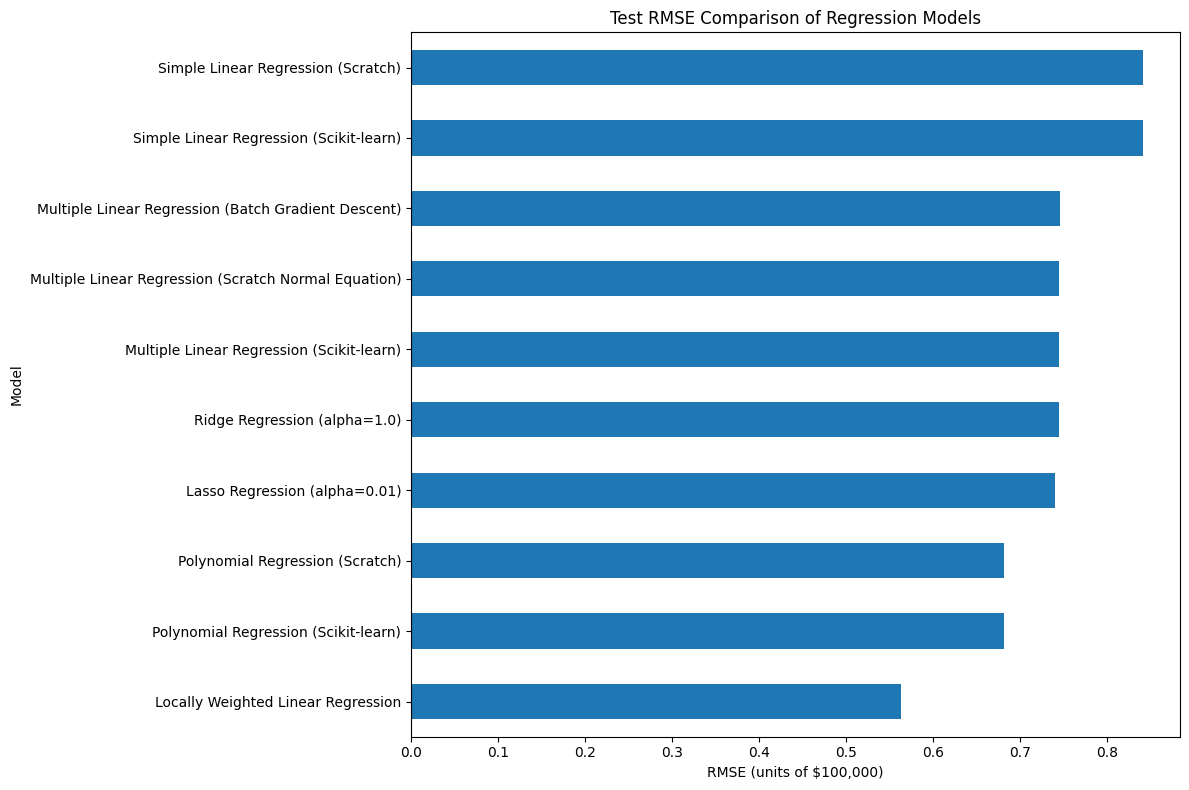

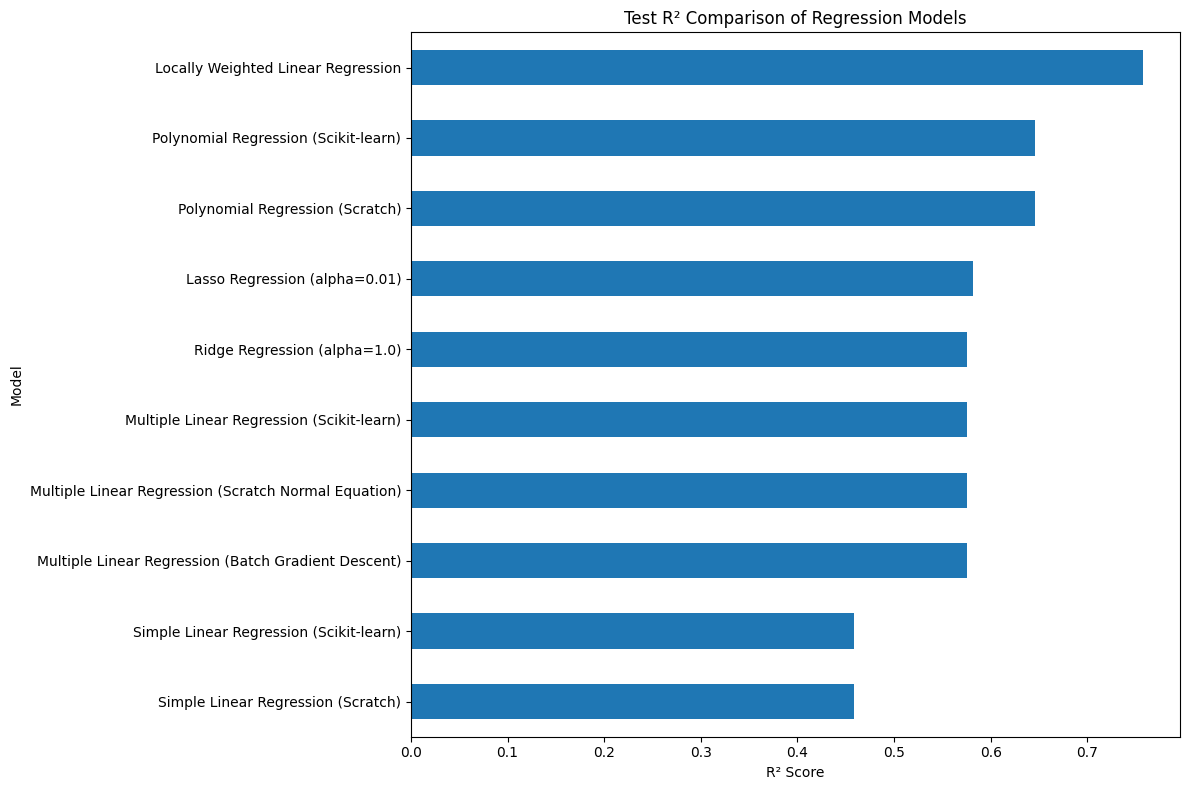

Best model by lowest RMSE: Locally Weighted Linear Regression
Best model by highest R²: Locally Weighted Linear Regression


In [25]:
final_comparison = pd.DataFrame(results).set_index("Model")

print("Final test-set comparison of all regression models:")
display(final_comparison.sort_values("RMSE").round(6))

# RMSE comparison
plt.figure(figsize=(12, 8))
final_comparison["RMSE"].sort_values().plot(kind="barh")
plt.xlabel("RMSE (units of $100,000)")
plt.ylabel("Model")
plt.title("Test RMSE Comparison of Regression Models")
plt.tight_layout()
plt.show()

# R-squared comparison
plt.figure(figsize=(12, 8))
final_comparison["R2"].sort_values().plot(kind="barh")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.title("Test R² Comparison of Regression Models")
plt.tight_layout()
plt.show()

print("Best model by lowest RMSE:", final_comparison["RMSE"].idxmin())
print("Best model by highest R²:", final_comparison["R2"].idxmax())

## 26. Actual vs Predicted Values

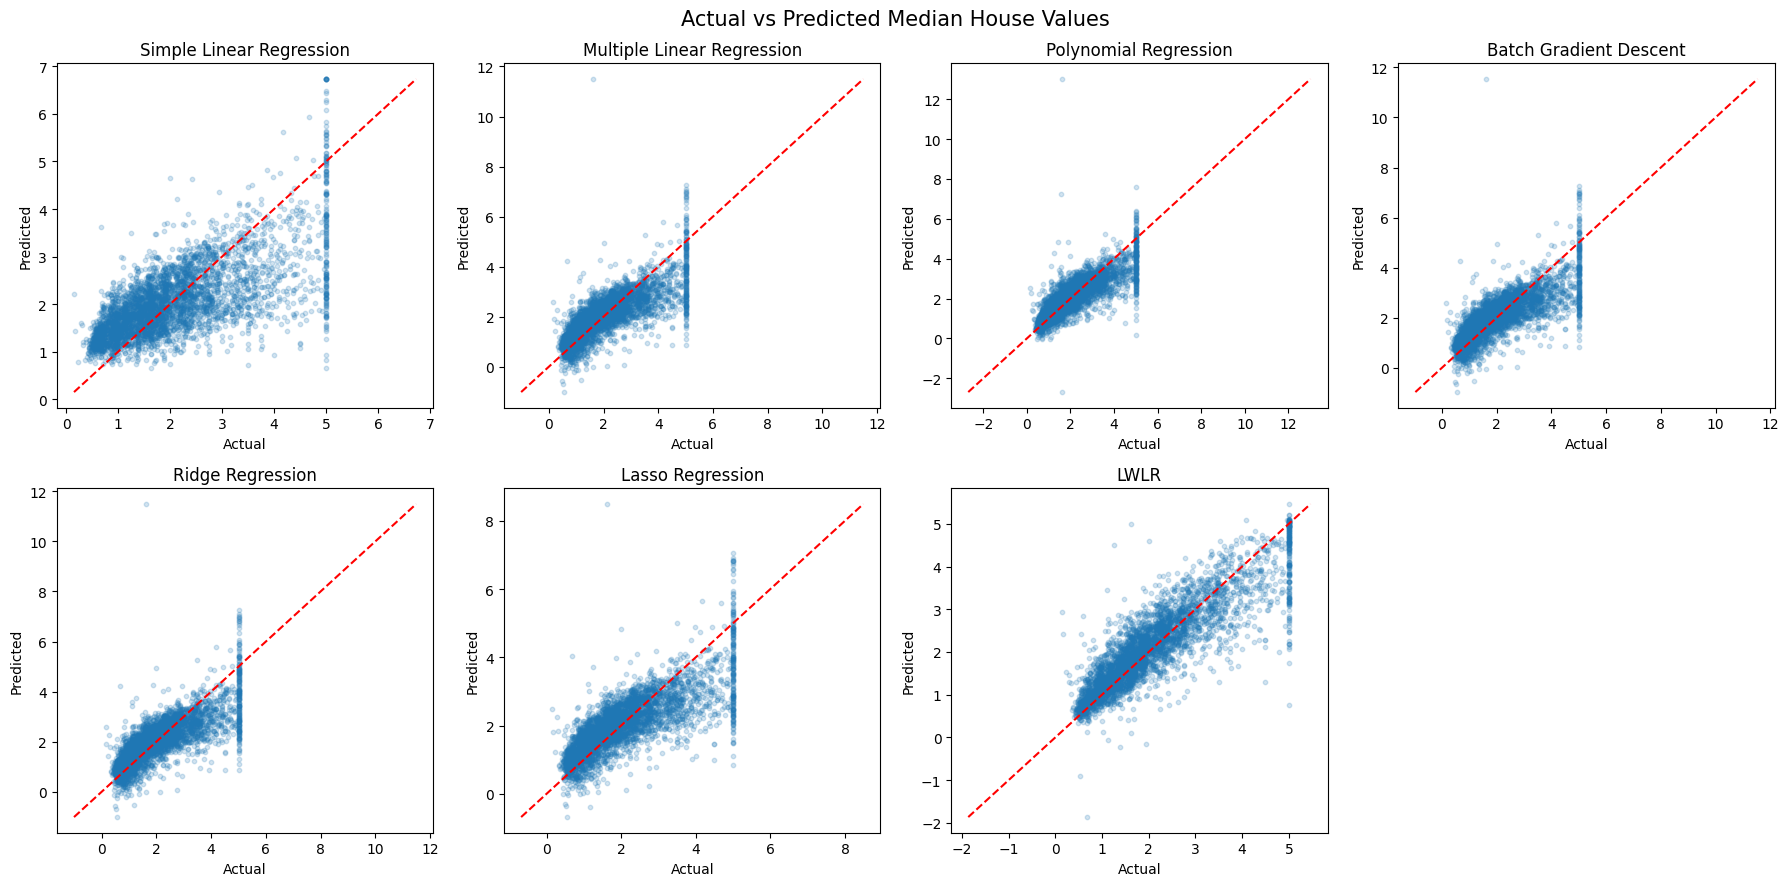

In [26]:
# Display actual-versus-predicted plots for selected models
selected_predictions = {
    "Simple Linear Regression": simple_pred,
    "Multiple Linear Regression": multiple_pred,
    "Polynomial Regression": polynomial_pred,
    "Batch Gradient Descent": gd_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "LWLR": lwlr_pred
}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.ravel()

for ax, (name, predictions) in zip(axes, selected_predictions.items()):
    ax.scatter(y_test, predictions, alpha=0.2, s=10)
    low = min(y_test.min(), np.min(predictions))
    high = max(y_test.max(), np.max(predictions))
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

axes[-1].axis("off")
plt.suptitle("Actual vs Predicted Median House Values", fontsize=15)
plt.tight_layout()
plt.show()

## 27. Critical Analysis

The performance of different regression models was evaluated using MAE, MSE, RMSE and R² Score. The following observations were made based on the final comparison table and visualisations.

**1. Simple vs Multiple Linear Regression:**

- Simple Linear Regression uses only Median Income (MedInc) to predict house value.
- Multiple Linear Regression uses all eight available predictors.
- Simple Linear Regression achieved an RMSE of 0.842090 and an R² score of 0.458859.
- Multiple Linear Regression achieved an RMSE of 0.745581 and an R² score of 0.575788.
- This shows that including additional housing and geographical features improves prediction performance compared with using only median income.

**2. Manual vs Library Implementations:**

- Simple Linear Regression was implemented manually using the Least Squares Method and also using Scikit-learn.
- Multiple Linear Regression was implemented manually using the Normal Equation and using Scikit-learn.
- Polynomial Regression was also implemented manually and using Scikit-learn.
- The corresponding manual and library implementations produced almost identical MAE, MSE, RMSE and R² values.
- This confirms that the mathematical implementations are consistent with the Scikit-learn implementations, with negligible numerical differences.

**3. Polynomial Regression:**

- Polynomial Regression uses squared and interaction features to capture nonlinear relationships.
- It achieved an RMSE of 0.681397 and an R² score of 0.645682.
- Its performance was better than Multiple Linear Regression, indicating that polynomial features helped capture additional relationships in the dataset.
- However, increasing model complexity can increase the risk of overfitting.

**4. Gradient Descent:**

- Batch Gradient Descent was implemented from scratch to optimise the parameters of Linear Regression.
- The training cost decreased from 0.500000 to 0.193743 over 2000 iterations.
- The convergence graph shows that the cost decreased rapidly during the initial iterations and gradually stabilised.
- Batch Gradient Descent achieved an RMSE of 0.745825 and an R² score of 0.575510.
- Its performance was very close to Scikit-learn Multiple Linear Regression, demonstrating that Gradient Descent can effectively optimise regression parameters when suitable learning-rate and iteration values are selected.

**5. Ridge and Lasso Regression:**

- Ridge Regression uses L2 regularisation to reduce the magnitude of regression coefficients.
- It achieved an RMSE of 0.745557 and an R² score of 0.575816, showing performance very close to ordinary Multiple Linear Regression.
- Lasso Regression uses L1 regularisation and can reduce less useful coefficients to zero.
- It achieved an RMSE of 0.740442 and an R² score of 0.581615.
- Lasso reduced the Population feature coefficient to zero, demonstrating its feature-selection capability.
- In this experiment, Lasso performed slightly better than ordinary Multiple Linear Regression in RMSE and R², while its MAE was marginally higher.

**6. Locally Weighted Linear Regression (LWLR):**

- LWLR fits a local regression model around each query observation by assigning higher weights to nearby training observations.
- It used a bandwidth (tau) of 1.0 and 250 nearest neighbours.
- It achieved an MAE of 0.396091, MSE of 0.317244, RMSE of 0.563244 and R² score of 0.757904.
- It produced the lowest RMSE and highest R² among all the implemented models.
- However, LWLR requires more computation because it fits a separate local model for each prediction. Its performance also depends on the bandwidth and number of neighbours selected.

**7. Overall Evaluation:**

- Lower MAE, MSE and RMSE indicate smaller prediction errors.
- Higher R² indicates that the model explains a greater proportion of the variation in the target variable.
- Locally Weighted Linear Regression achieved the best overall test performance in this experiment.
- Polynomial Regression was the second-best model based on RMSE.
- Manual and Scikit-learn implementations produced nearly identical results for the corresponding regression methods.

Overall, the experiment demonstrates that regression performance depends on feature selection, model complexity, regularisation, optimisation techniques and the relationships present in the dataset.

## 28. Conclusion

The experiment successfully implemented and evaluated different regression techniques using the California Housing dataset, which contains 20,640 observations and eight numerical predictors. The objective was to predict median house values and compare the performance of different regression and optimisation methods.


Simple Linear Regression, Multiple Linear Regression and Polynomial Regression were implemented both manually and using Scikit-learn. The manual implementations using the Least Squares Method and Normal Equation produced results nearly identical to their corresponding library implementations, confirming the correctness of the mathematical approaches.

Batch Gradient Descent was implemented from scratch to understand iterative optimisation. The training cost decreased from 0.500000 to 0.193743, demonstrating successful convergence with the selected learning rate and number of iterations.

Ridge and Lasso Regression were implemented to understand L2 and L1 regularisation. Lasso achieved a slightly better RMSE and R² score than ordinary Multiple Linear Regression and reduced the coefficient of the Population feature to zero. Locally Weighted Linear Regression was also implemented to study local model fitting based on distances between observations.

Among all the implemented models, Locally Weighted Linear Regression achieved the best performance, with an RMSE of 0.563244 and an R² score of 0.757904. Polynomial Regression was the next strongest model, with an RMSE of 0.681397 and an R² score of 0.645682.

The experiment demonstrates that regression performance depends on feature selection, model complexity, optimisation techniques, regularisation and the underlying relationships present in the dataset. It also provides practical understanding of implementing regression algorithms manually and evaluating their performance using appropriate metrics.

Thus, all the major objectives of the practical were achieved, including regression modelling, Least Squares estimation, Gradient Descent optimisation, comparison of manual and library implementations, and exploration of Ridge, Lasso and Locally Weighted Linear Regression.

#**Github Link**
[click here](https://github.com/siddheshmane18/AIML_SEM5/tree/main/Continuous%20Assessment)